# Emotion Detection

In [1]:
import pandas as pd
import numpy as np

In [2]:
pd.read_csv(r"C:\Users\Admin\Downloads\emotion_nlp.csv")

,Text,Emotions
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger
...,...,...
17994,i just keep feeling like someone is being unki...,anger
17995,im feeling a little cranky negative after this...,anger
17996,i feel that i am useful to my people and that ...,joy
17997,im feeling more comfortable with derby i feel ...,joy


In [3]:
em=pd.read_csv(r"C:\Users\Admin\Downloads\emotion_nlp.csv")

In [4]:
em.Emotions.value_counts()

Emotions
joy         6056
sadness     5247
anger       2434
fear        2161
love        1463
surprise     638
Name: count, dtype: int64

In [5]:
em.isnull().sum()[em.isnull().sum()>0]

Series([], dtype: int64)

In [6]:
em.Emotions.unique()

array(['sadness', 'anger', 'love', 'surprise', 'fear', 'joy'],
      dtype=object)

In [7]:
em=em.rename(columns={'Emotions':'y','Text':'x'})

In [8]:
em.head()

,x,y
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger


In [9]:
em=em.replace({'sadness':1,'anger':2,'love':3,'surprise':4,'fear':5,'joy':6})
em

C:\Users\Admin\AppData\Local\Temp\ipykernel_14744\4190060271.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  em=em.replace({'sadness':1,'anger':2,'love':3,'surprise':4,'fear':5,'joy':6})


,x,y
0,i didnt feel humiliated,1
1,i can go from feeling so hopeless to so damned...,1
2,im grabbing a minute to post i feel greedy wrong,2
3,i am ever feeling nostalgic about the fireplac...,3
4,i am feeling grouchy,2
...,...,...
17994,i just keep feeling like someone is being unki...,2
17995,im feeling a little cranky negative after this...,2
17996,i feel that i am useful to my people and that ...,6
17997,im feeling more comfortable with derby i feel ...,6


In [10]:
em.x=em.x.str.lower() 
em.x

0                                  i didnt feel humiliated
1        i can go from feeling so hopeless to so damned...
2         im grabbing a minute to post i feel greedy wrong
3        i am ever feeling nostalgic about the fireplac...
4                                     i am feeling grouchy
                               ...                        
17994    i just keep feeling like someone is being unki...
17995    im feeling a little cranky negative after this...
17996    i feel that i am useful to my people and that ...
17997    im feeling more comfortable with derby i feel ...
17998    i feel all weird when i have to meet w people ...
Name: x, Length: 17999, dtype: object

In [11]:
import nltk   # NLP
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Admin\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [12]:
from nltk.corpus import stopwords
len(stopwords.words('english')) # only stopwords
# stopwords remove them

198

In [13]:
import string
string.punctuation# only punctuation
len(string.punctuation)

32

In [14]:
l1=list(stopwords.words('english'))
l1

['a',
 'about',
 'above',
 'after',
 'again',
 'against',
 'ain',
 'all',
 'am',
 'an',
 'and',
 'any',
 'are',
 'aren',
 "aren't",
 'as',
 'at',
 'be',
 'because',
 'been',
 'before',
 'being',
 'below',
 'between',
 'both',
 'but',
 'by',
 'can',
 'couldn',
 "couldn't",
 'd',
 'did',
 'didn',
 "didn't",
 'do',
 'does',
 'doesn',
 "doesn't",
 'doing',
 'don',
 "don't",
 'down',
 'during',
 'each',
 'few',
 'for',
 'from',
 'further',
 'had',
 'hadn',
 "hadn't",
 'has',
 'hasn',
 "hasn't",
 'have',
 'haven',
 "haven't",
 'having',
 'he',
 "he'd",
 "he'll",
 'her',
 'here',
 'hers',
 'herself',
 "he's",
 'him',
 'himself',
 'his',
 'how',
 'i',
 "i'd",
 'if',
 "i'll",
 "i'm",
 'in',
 'into',
 'is',
 'isn',
 "isn't",
 'it',
 "it'd",
 "it'll",
 "it's",
 'its',
 'itself',
 "i've",
 'just',
 'll',
 'm',
 'ma',
 'me',
 'mightn',
 "mightn't",
 'more',
 'most',
 'mustn',
 "mustn't",
 'my',
 'myself',
 'needn',
 "needn't",
 'no',
 'nor',
 'not',
 'now',
 'o',
 'of',
 'off',
 'on',
 'once',
 'on

In [15]:
def text_process(mess):
    """
    1.remove punction
    2.remove stopwords
    3.return the list of clean yextwords

    """
    nopunc=[char for char in mess if char not in string.punctuation]
    nopunc="".join(nopunc)
    
    return[word for word in nopunc.split() if word not in l1]

In [16]:
em['x'].apply(text_process)

0                                [didnt, feel, humiliated]
1        [go, feeling, hopeless, damned, hopeful, aroun...
2        [im, grabbing, minute, post, feel, greedy, wrong]
3        [ever, feeling, nostalgic, fireplace, know, st...
4                                       [feeling, grouchy]
                               ...                        
17994    [keep, feeling, like, someone, unkind, wrong, ...
17995    [im, feeling, little, cranky, negative, doctor...
17996    [feel, useful, people, gives, great, feeling, ...
17997    [im, feeling, comfortable, derby, feel, though...
17998    [feel, weird, meet, w, people, text, like, don...
Name: x, Length: 17999, dtype: object

In [17]:
from sklearn.feature_extraction.text import CountVectorizer

In [18]:
import timeit
start=timeit.default_timer()

bow_transformer=CountVectorizer(analyzer=text_process).fit(em['x'])

stop=timeit.default_timer()
execution_time=stop-start
print('program execution in ',execution_time)

program execution in  1.348092700001871


In [19]:
bow_transformer.vocabulary_

{'didnt': 3834,
 'feel': 5205,
 'humiliated': 6786,
 'go': 5997,
 'feeling': 5209,
 'hopeless': 6687,
 'damned': 3392,
 'hopeful': 6685,
 'around': 726,
 'someone': 13096,
 'cares': 2062,
 'awake': 974,
 'im': 6920,
 'grabbing': 6058,
 'minute': 8934,
 'post': 10731,
 'greedy': 6120,
 'wrong': 15877,
 'ever': 4830,
 'nostalgic': 9576,
 'fireplace': 5342,
 'know': 7832,
 'still': 13463,
 'property': 11032,
 'grouchy': 6160,
 'ive': 7442,
 'little': 8241,
 'burdened': 1870,
 'lately': 7950,
 'wasnt': 15482,
 'sure': 13811,
 'taking': 13975,
 'milligrams': 8890,
 'times': 14361,
 'recommended': 11455,
 'amount': 484,
 'fallen': 5093,
 'asleep': 798,
 'lot': 8351,
 'faster': 5140,
 'also': 429,
 'like': 8164,
 'funny': 5747,
 'confused': 2837,
 'life': 8137,
 'teenager': 14091,
 'jaded': 7458,
 'year': 15934,
 'old': 9767,
 'man': 8527,
 'petronas': 10378,
 'years': 15942,
 'performed': 10304,
 'well': 15573,
 'made': 8463,
 'huge': 6763,
 'profit': 10985,
 'romantic': 11990,
 'make': 8501

In [20]:
len(bow_transformer.vocabulary_)

16035

In [21]:
tdm=bow_transformer.transform(em['x'])

In [22]:
tdm.shape

(17999, 16035)

In [23]:
from sklearn.model_selection import train_test_split
tdm_train,tdm_test,train_y,test_y=train_test_split(tdm,em['y'],test_size=.2)

In [24]:
from sklearn.naive_bayes import MultinomialNB
nb=MultinomialNB()

In [25]:
nb.fit(tdm_train,train_y)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None


In [26]:
pred_nb=nb.predict(tdm_test)

In [27]:
from sklearn.metrics import confusion_matrix,accuracy_score,recall_score,classification_report


In [28]:
tab_nb=confusion_matrix(test_y,pred_nb)
tab_nb

array([[ 987,   12,    1,    2,    8,   44],
       [  90,  335,    2,    0,   14,   55],
       [  43,    1,   97,    0,    2,  152],
       [  40,    2,    2,   14,   16,   47],
       [  86,   18,    2,    3,  267,   47],
       [  60,    8,   11,    0,    4, 1128]])

In [29]:
accuracy_score(test_y,pred_nb)*100

78.55555555555556

In [30]:
print(classification_report(test_y,pred_nb))

              precision    recall  f1-score   support

           1       0.76      0.94      0.84      1054
           2       0.89      0.68      0.77       496
           3       0.84      0.33      0.47       295
           4       0.74      0.12      0.20       121
           5       0.86      0.63      0.73       423
           6       0.77      0.93      0.84      1211

    accuracy                           0.79      3600
   macro avg       0.81      0.60      0.64      3600
weighted avg       0.80      0.79      0.76      3600



In [31]:
from sklearn.ensemble import RandomForestClassifier
rfc=RandomForestClassifier()

In [32]:
rfc.fit(tdm_train,train_y)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [33]:
pred_rfc = rfc.predict(tdm_test)

In [34]:
tab_rfc = confusion_matrix(test_y,pred_rfc)
tab_rfc

array([[ 965,   31,    4,    7,   23,   24],
       [  20,  436,    1,    1,   19,   19],
       [   2,    2,  215,    1,    2,   73],
       [   3,    0,    0,   95,   17,    6],
       [  12,   17,    2,   30,  360,    2],
       [  37,   13,   36,   15,   13, 1097]])

In [35]:
accuracy_score(test_y,pred_rfc)

0.88

In [36]:
from sklearn.linear_model import LogisticRegression
logreg=LogisticRegression()
logreg.fit(tdm_train , train_y)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [37]:
pred_log = logreg.predict(tdm_test)

In [38]:
from sklearn.metrics import confusion_matrix

In [39]:
tab_log = confusion_matrix(test_y , pred_log)
tab_log

array([[ 983,   24,    3,    4,   16,   24],
       [  30,  427,    2,    3,   13,   21],
       [   3,    2,  227,    0,    1,   62],
       [   8,    1,    0,   84,   17,   11],
       [  18,   13,    0,   19,  361,   12],
       [  29,    5,   32,    8,    7, 1130]])

In [40]:
accuracy_score(test_y , pred_log)

0.8922222222222222

In [41]:
import matplotlib.pyplot as plt

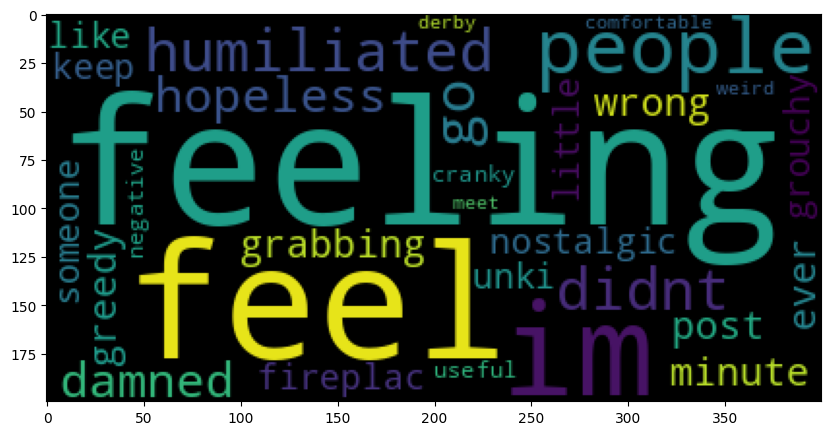

In [42]:
from wordcloud import WordCloud
cloud=WordCloud(stopwords=stopwords.words('english'),max_words=30).generate(str(em['x']))
plt.figure(figsize=(10,10))
plt.imshow(cloud)

In [43]:
em.y.value_counts()

y
6    6056
1    5247
2    2434
5    2161
3    1463
4     638
Name: count, dtype: int64

In [44]:
em_emo_df=em[em.y==1]

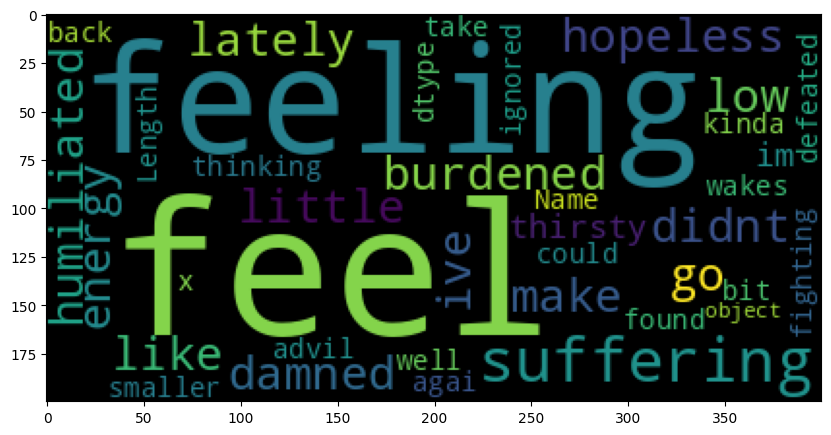

In [45]:
from wordcloud import WordCloud
cloud=WordCloud(stopwords=stopwords.words('english'),max_words=40).generate(str(em_emo_df['x']))
plt.figure(figsize=(10,10))
plt.imshow(cloud)

In [46]:
em_emo_df1=em[em.y==2]

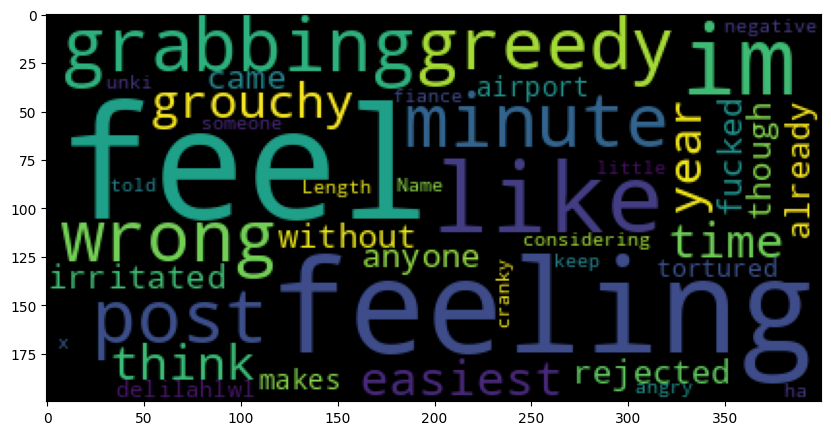

In [47]:
cloud=WordCloud(stopwords=stopwords.words('english'),max_words=40).generate(str(em_emo_df1['x']))
plt.figure(figsize=(10,10))
plt.imshow(cloud)

In [48]:
em_emo_df2=em[em.y==3]

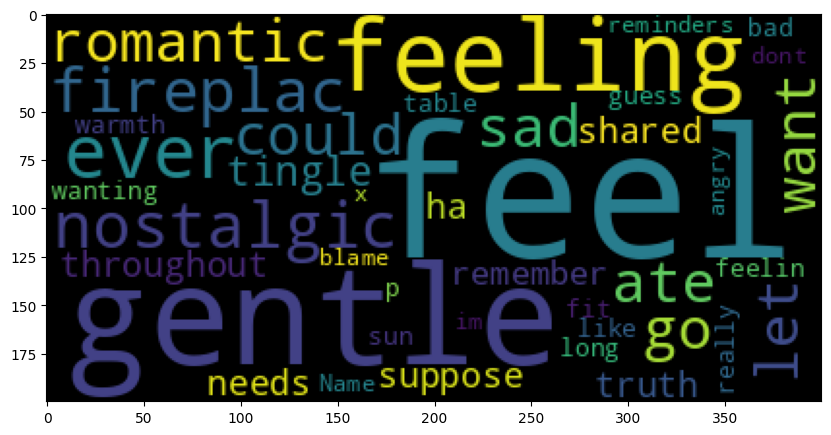

In [49]:
cloud=WordCloud(stopwords=stopwords.words('english'),max_words=40).generate(str(em_emo_df2['x']))
plt.figure(figsize=(10,10))
plt.imshow(cloud)